# Assignment 09, Problem 2 — Hussein Jawad
**E89 Deep Learning · Speech analysis: spectrogram and MFCCs of my own voice** (based on Lecture 9, the class notebook
`lec09_speech_analysis.ipynb` and the lab notebook `01_lab09_speech_mfcc_piper.ipynb`)

---

# Problem 2: Spectrogram and MFCCs of "Rice University"
Find a way to record the phrase "Rice University" in your own voice. Make it as short as possible. Calculate and display
the spectrogram of that recording. Determine the first 12 MFCC-s for every frame of length 25 msec with the stride of
10 msec. Display as a colorful 2D image the collection of those MFCC-s. Use every 3rd frame. Use any color schema of your
choice. Use `librosa` or any other suitable Python package to calculate the spectrogram and MFCC-s.

## Approach

### Goal
Record "Rice University" in my own voice, keep only the spoken phrase, and show two pictures of it: the **spectrogram**
(how strong each frequency is at each moment; Lecture 9, slide 40 shows one for the same phrase) and the first 12
**MFCCs** of every 3rd frame (a compact description of the shape of the spectrum in each frame).

### Settings

| Setting | Value |
|---|---|
| Recording | my voice, recorded in Colab with the browser microphone; `rice_university.wav` in the GitHub repository |
| Sample rate | 16,000 Hz (frequencies up to 8,000 Hz) |
| Frame length / stride | 25 ms = 400 samples / 10 ms = 160 samples |
| Window, FFT size | Hann, 400 (one FFT per frame, bins 40 Hz apart) |
| Mel filters, MFCCs | 40 filters, first 12 coefficients $c_0 \dots c_{11}$ |
| MFCC image | every 3rd frame (one column every 30 ms), "turbo" colors |

### Steps

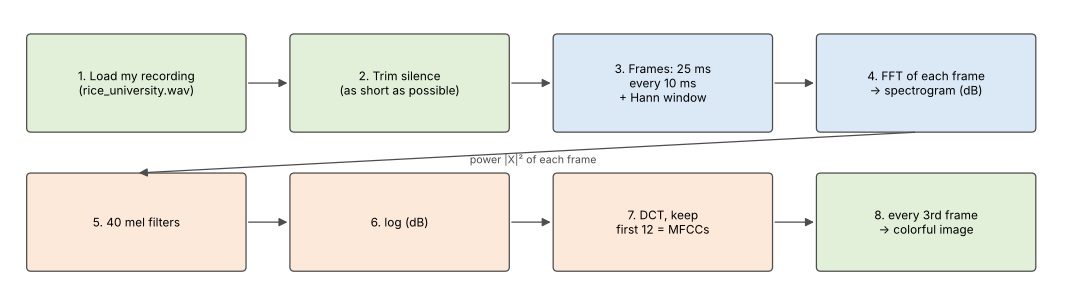

1. **Load** my recording (Steps 2–3).
2. **Trim** the silence at both ends to make it as short as possible (Step 4).
3. **Spectrogram** of 25 ms frames every 10 ms (Step 5, A.1–A.3).
4. **MFCCs:** the first 12 of every frame (Step 6, A.4–A.5).
5. **Image** of every 3rd frame of the MFCCs (Step 7).

### Code
The librosa calls follow `lec09_speech_analysis.ipynb` (`librosa.load`, `librosa.feature.mfcc`,
`librosa.display.specshow`) and the frame settings follow the lab notebook (400-sample frames, 160-sample hop,
`center=False`, 40 mel filters). Step 2 downloads my recording from GitHub when it is not next to the notebook.

## Solution

### Step 1: Imports

In [1]:
import os                                    # check whether the recording file already exists
import urllib.request                        # download the recording from GitHub
import numpy as np                           # numerical arrays
import matplotlib.pyplot as plt              # plotting
import librosa                               # audio loading, spectrogram and MFCC calculation
import librosa.display                       # specshow: draws a spectrogram with time and frequency axes
import IPython.display as ipd                # play audio inside the notebook

### Step 2: My recording of "Rice University"
I recorded the phrase in Google Colab with the browser's microphone (JavaScript `MediaRecorder`) and converted it with
`ffmpeg` to `rice_university.wav` (16,000 samples per second, mono). The file is stored in the GitHub repository next to
this notebook; the cell below uses the local copy if it exists and otherwise downloads it.

In [2]:
AUDIO_FILE = "rice_university.wav"           # my recording of "Rice University"
AUDIO_URL = ("https://raw.githubusercontent.com/jawad197704/"   # the same file in the GitHub repository
             "e89_Hussein_Jawad_HW09/main/rice_university.wav")  # (main branch)

if not os.path.exists(AUDIO_FILE):           # e.g. in Colab, where only the notebook is opened
    urllib.request.urlretrieve(AUDIO_URL, AUDIO_FILE)  # download the recording from GitHub
print("Using the recording:", AUDIO_FILE)    # confirm which file is analyzed

Using the recording: rice_university.wav


### Step 3: Load the recording

In [3]:
y_full, sr = librosa.load(AUDIO_FILE, sr=16000)   # read the file as mono samples in [-1, 1], resampled to 16 kHz
print(f"sample rate: {sr} Hz | duration: {len(y_full) / sr:.3f} s")  # basic facts about the recording
ipd.display(ipd.Audio(y_full, rate=sr))           # play the full recording

sample rate: 16000 Hz | duration: 3.000 s


### Step 4: Make the recording as short as possible
`librosa.effects.trim` removes the frames at both ends that are more than `TOP_DB` = 35 dB quieter than the loudest frame.
Listen to the result: if the "R" or the "-ty" was cut off, increase `TOP_DB` (e.g. 40); if silence remains, decrease it.

In [4]:
WIN = int(0.025 * sr)                        # frame length: 25 ms = 400 samples at 16 kHz
HOP = int(0.010 * sr)                        # stride between frames: 10 ms = 160 samples
TOP_DB = 35                                  # frames more than 35 dB below the loudest frame count as silence

y, (start, end) = librosa.effects.trim(y_full, top_db=TOP_DB, frame_length=WIN, hop_length=HOP)  # cut both ends
print(f"trimmed: {len(y) / sr:.3f} s (was {len(y_full) / sr:.3f} s)")  # length before and after trimming
ipd.display(ipd.Audio(y, rate=sr))           # listen: the whole phrase must still be there

trimmed: 1.490 s (was 3.000 s)


### Step 5: The spectrogram
Each 25 ms frame (Hann window, 10 ms stride) becomes one column: 201 frequency bins from 0 to 8,000 Hz, in dB relative to
the loudest point.

spectrogram shape (frequency bins, frames): (201, 147)


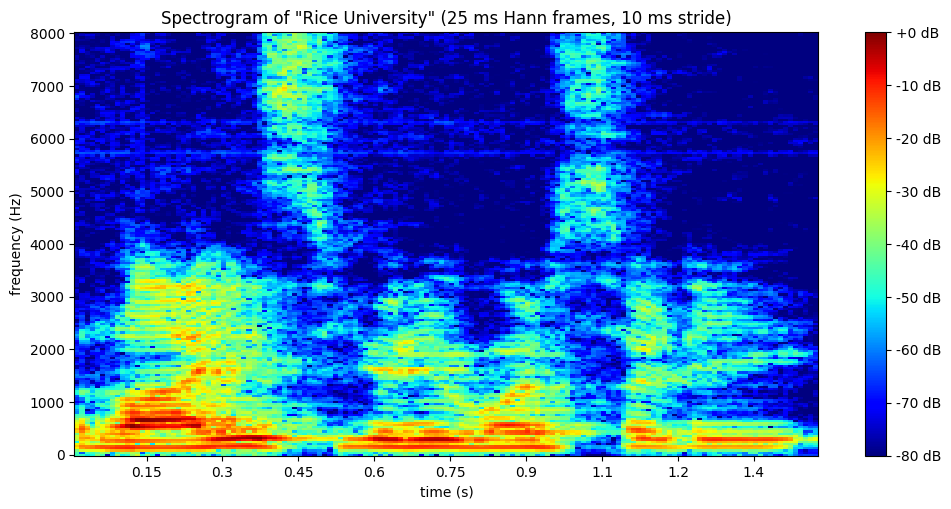

In [5]:
S = librosa.stft(y, n_fft=WIN, win_length=WIN, hop_length=HOP,   # FFT of every 25 ms frame, 10 ms apart,
                 window="hann", center=False)                    # with a Hann window and no padding at the ends
S_db = librosa.amplitude_to_db(np.abs(S), ref=np.max)            # magnitude in dB; 0 dB = loudest point
t_frames = (np.arange(S.shape[1]) * HOP + WIN / 2) / sr          # time at the middle of each frame, in seconds
print("spectrogram shape (frequency bins, frames):", S.shape)    # 201 bins, one column per frame

fig, ax = plt.subplots(figsize=(12, 5.5))                        # one wide figure
img = librosa.display.specshow(S_db, sr=sr, hop_length=HOP, x_coords=t_frames,  # draw the dB values at frame times
                               x_axis="time", y_axis="hz",                     # time across, frequency (Hz) up
                               cmap="jet", vmin=-80, vmax=0, ax=ax)             # colorful scale from -80 to 0 dB
ax.set_title('Spectrogram of "Rice University" (25 ms Hann frames, 10 ms stride)')  # plot title
ax.set_xlabel("time (s)")                                        # horizontal axis label
ax.set_ylabel("frequency (Hz)")                                  # vertical axis label
fig.colorbar(img, ax=ax, format="%+.0f dB")                      # color scale in dB
plt.show()                                                       # render the figure

### Step 6: The first 12 MFCCs of every frame
Same frames as Step 5; for each frame librosa computes the power spectrum, 40 mel filter energies, their log and a DCT,
and keeps the first 12 values, $c_0 \dots c_{11}$. ($c_0$ reflects the overall level of the frame; the lecture's recipe
lists 12 cepstral coefficients plus the frame energy as a 13th feature, Lecture 9, slides 79 and 83.)

In [6]:
N_MFCC = 12                                  # the problem asks for the first 12 MFCCs
N_MELS = 40                                  # number of mel filters (as in the lab notebook)

mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC,          # first 12 MFCCs of every frame:
                            n_fft=WIN, win_length=WIN, hop_length=HOP,  # 25 ms frames every 10 ms (as in Step 5),
                            window="hann", center=False,         # Hann window, no padding at the ends,
                            n_mels=N_MELS)                       # 40 mel filters
print("MFCC array shape (coefficients, frames):", mfcc.shape)  # 12 rows, one column per frame

MFCC array shape (coefficients, frames): (12, 147)


### Step 7: Every 3rd frame as a colorful 2D image
Columns are frames 0, 3, 6, … (one every 30 ms); rows are $c_0$ (bottom) to $c_{11}$ (top).

kept frames: 49 of 147


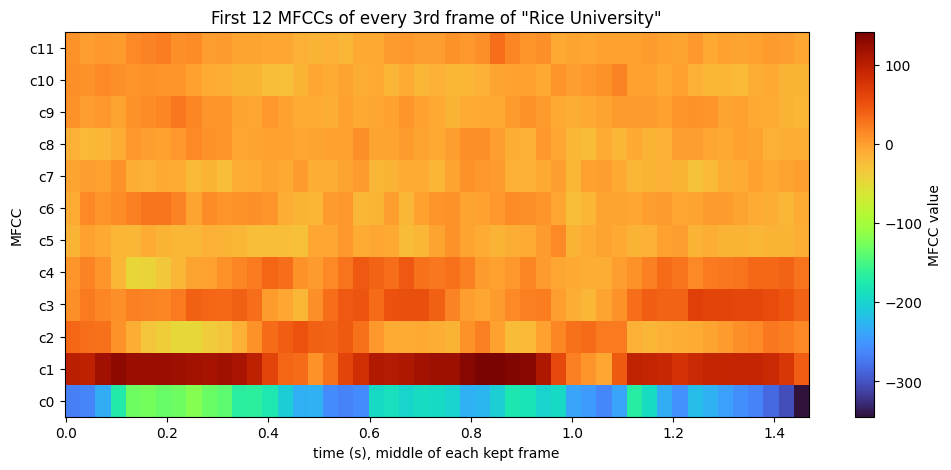

In [7]:
mfcc3 = mfcc[:, ::3]                         # keep every 3rd frame: frames 0, 3, 6, ...
t3 = t_frames[::3]                           # middle times of the kept frames
print("kept frames:", mfcc3.shape[1], "of", mfcc.shape[1])  # how many columns the image has

fig, ax = plt.subplots(figsize=(12, 5))                         # one wide figure
im = ax.imshow(mfcc3, aspect="auto", origin="lower", cmap="turbo",   # colorful image, c0 at the bottom,
               extent=[t3[0] - 0.015, t3[-1] + 0.015, -0.5, N_MFCC - 0.5],  # each column 30 ms wide
               interpolation="nearest")                         # one sharp block per value
ax.set_yticks(range(N_MFCC))                                    # one tick per coefficient
ax.set_yticklabels([f"c{i}" for i in range(N_MFCC)])            # label the rows c0 ... c11
ax.set_xlabel("time (s), middle of each kept frame")           # horizontal axis label
ax.set_ylabel("MFCC")                                           # vertical axis label
ax.set_title('First 12 MFCCs of every 3rd frame of "Rice University"')  # plot title
fig.colorbar(im, ax=ax, label="MFCC value")                     # color scale
plt.show()                                                      # render the figure

## Results and discussion
* **Recording:** 3.0 s recorded, **1.49 s** after trimming the silence; 147 frames, 49 of them in the MFCC image.
* **Spectrogram** (compare Lecture 9, slide 40): the vowels of "Rice" (about 0.05–0.4 s), "Univer-" (0.55–0.95 s),
  "-si-" (1.1–1.17 s) and "-ty" (1.25–1.42 s) are the bright parts: evenly spaced horizontal lines (the **harmonics** of
  the voice) with brighter bands across them (the **formants**). The two **"s"** sounds (about 0.42–0.5 s and
  1.0–1.08 s) look different: noise between about 4,000 and 8,000 Hz with no harmonics. The dark gaps are the short pause
  between the two words (about 0.51 s) and the closure of the "t" in "-ty" (about 1.2 s). The faint horizontal lines near
  5,700 and 6,300 Hz that run through the whole recording are a steady background tone from the recording setup, not
  speech.
* **MFCC image:** each column describes the shape of the spectrum of one 25 ms frame with 12 numbers instead of 201.
  $c_0$ (proportional to the average log mel energy; about −350 to −120) is far below the other coefficients, so its row
  is blue-green while $c_1 \dots c_{11}$ are orange-red. $c_1$ (low vs high
  frequencies) averages about 90–120 in the vowels and drops to about 30 in the first "s" and about 0 in the
  second. The columns change at the
  boundaries between sounds, which is what makes MFCCs useful features for speech recognition.

---
# Appendix: From a recording to MFCCs

## A.1 Frames and the Hann window
Speech changes all the time but is nearly steady over a few tens of milliseconds, so it is cut into short overlapping
frames (Lecture 9, slide 36: typically 10–25 ms, shifted by 5–10 ms); here 25 ms long, a new one every 10 ms. Each frame is multiplied by a Hann window, which fades it
in and out so the FFT does not see sharp edges (slide 38). "Every 3rd frame" means one frame every 30 ms.

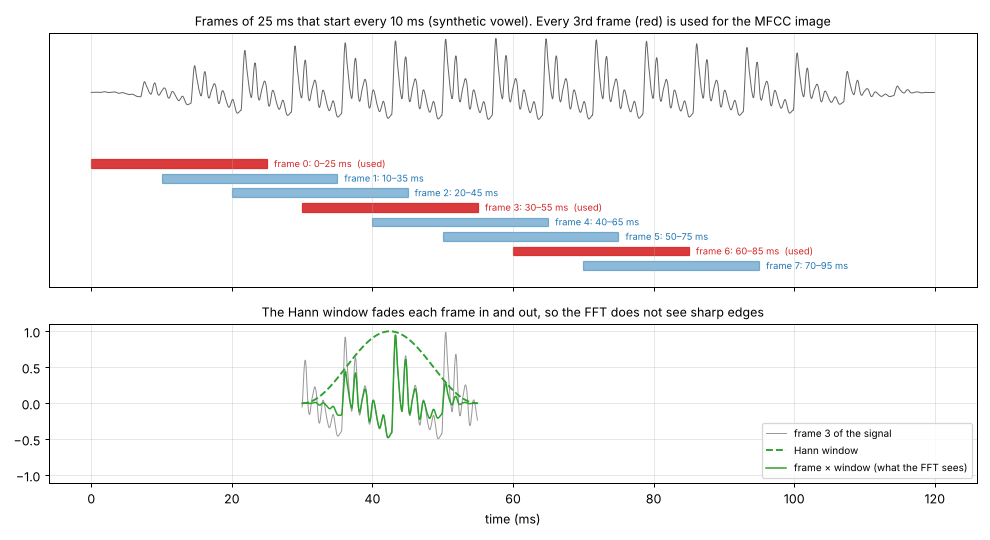

## A.2 One frame → one column: harmonics and formants
The FFT of a frame shows how strong each frequency is; the spectra of all frames side by side form the spectrogram. In a
vowel, the vocal cords produce **harmonics** (peaks at every multiple of the pitch frequency) and the mouth and throat shape them into
**formants** (the smooth envelope's peaks F1, F2, F3), which identify the vowel (source–filter model, Lecture 9, slide 8).

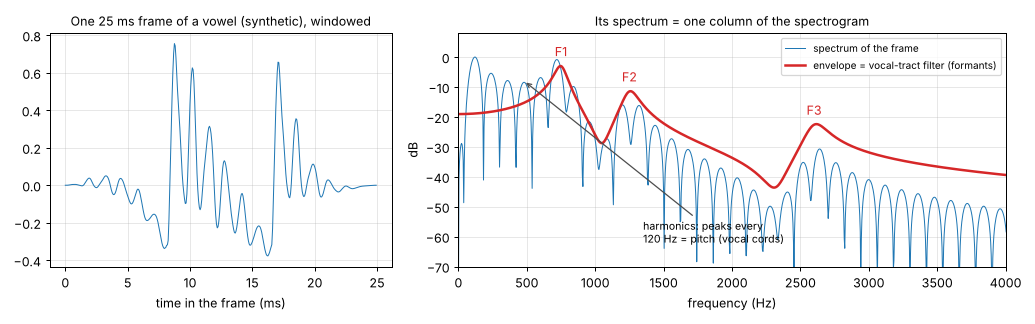

## A.3 Reading a speech spectrogram
Vowels: harmonics and formants. "s": noise at high frequencies, no harmonics. Silence: dark. Formants move when a vowel
glides, e.g. F2 rises in "Rice" (/aɪ/) and falls in "U" (/ju/). Synthetic example with the same settings:

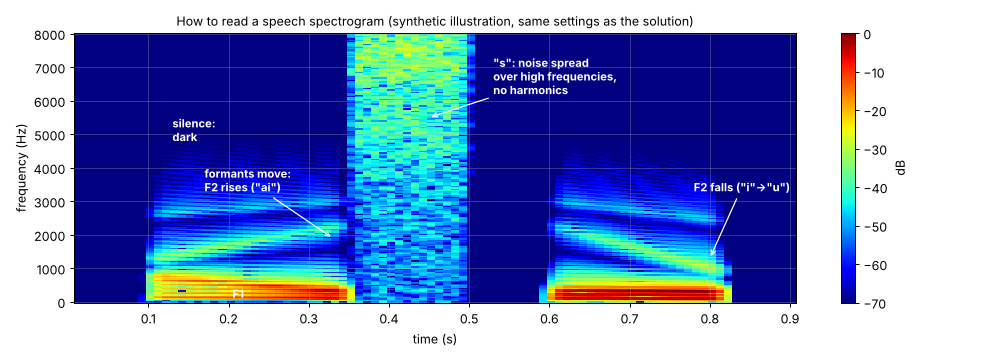

## A.4 Mel filter bank
We hear pitch differences much better at low frequencies than at high ones. The **mel scale** follows our hearing
(the curve on Lecture 9, slide 52 is $\text{mel} = 2595\log_{10}(1 + f/700)$; librosa's default is the closely
related Slaney version). 40
triangular filters equally spaced in mel (narrow at low, wide at high frequencies) turn the 201 FFT values of a frame
into 40 mel energies (Lecture 9, slides 64–66).

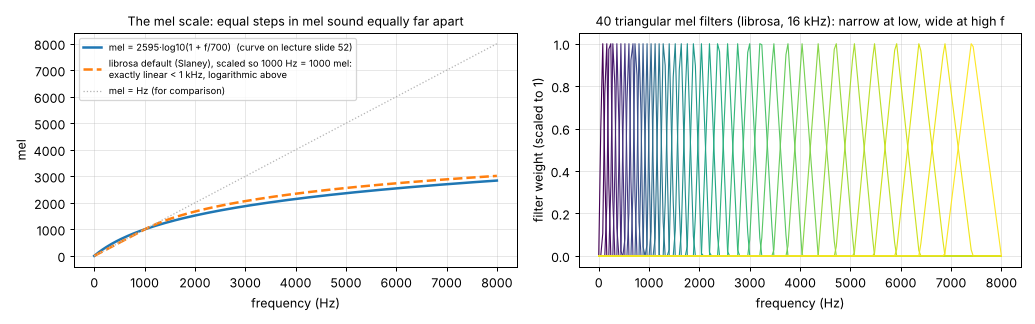

## A.5 Log and DCT → MFCCs
The 40 mel energies are converted to a log scale (dB), and a **discrete cosine transform** describes them as a sum of
cosine patterns; MFCC $c_n$ is the amount of pattern $n$ (Lecture 9, slides 67–78). $c_0$ (flat pattern) is proportional to the
average log energy, $c_1$ compares low with high frequencies, and higher coefficients describe finer detail. Keeping the first
12 keeps the smooth envelope (the formants) and drops the fine detail (the pitch harmonics).

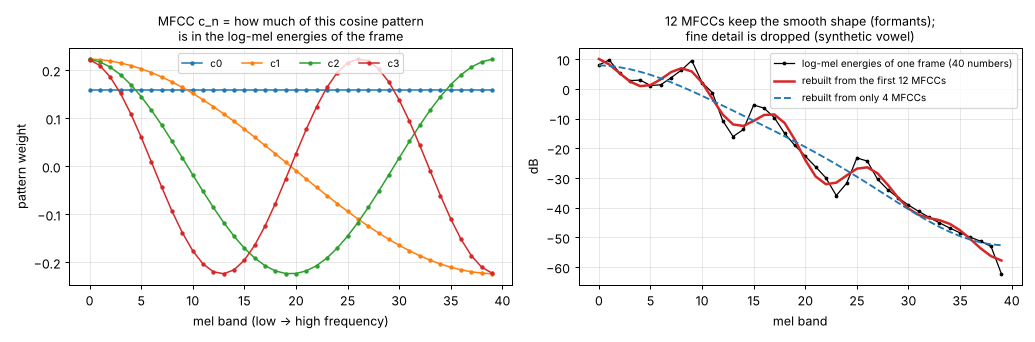